# 01 — Tratamento e preparação da base de dados

**Projeto:** NPS Preditivo — Tech Challenge Fase 1 (Pós Tech FIAP)

**Objetivo deste notebook:** garantir que a base esteja confiável antes de qualquer análise. Aqui nós:

1. carregamos a base e conferimos se todas as colunas do dicionário de dados existem;
2. avaliamos a qualidade (nulos, duplicados, tipos, faixas de valores);
3. checamos **regras de negócio** que indicam possíveis erros de registro;
4. avaliamos outliers e decidimos o que fazer com eles;
5. criamos variáveis derivadas úteis para a análise e para o modelo;
6. identificamos variáveis que **não podem** entrar no modelo (risco de vazamento de dados);
7. salvamos a base tratada em `data/processed/nps_tratado.csv`.

> As funções usadas aqui estão em `src/data_preparation.py`, para que o mesmo tratamento seja reaproveitado na EDA e no modelo.

In [1]:
# Configuração: permite importar o pacote "src" a partir da pasta notebooks/
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.data_preparation import (
    load_raw_data, build_quality_report, check_business_rules, count_iqr_outliers,
    prepare_dataset, save_processed_data, calculate_nps,
)
from src.visualization import set_plot_style

set_plot_style()
pd.set_option("display.max_columns", 50)

## 1. Carga da base

In [2]:
raw_df = load_raw_data()
print(f"Linhas: {raw_df.shape[0]:,} | Colunas: {raw_df.shape[1]}")
raw_df.head()

Linhas: 2,500 | Colunas: 19


,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


In [3]:
# Granularidade: cada linha é um pedido? Cada cliente aparece quantas vezes?
print("Pedidos únicos :", raw_df["order_id"].nunique())
print("Clientes únicos:", raw_df["customer_id"].nunique())

Pedidos únicos : 2500
Clientes únicos: 2500


**Leitura:** a base tem **2.500 pedidos de 2.500 clientes diferentes** — ou seja, uma linha por cliente/pedido.
Isso simplifica a análise (não há histórico de várias compras do mesmo cliente), mas também é uma **limitação**: não conseguimos acompanhar a evolução da satisfação de um mesmo cliente ao longo do tempo.

## 2. Visão geral da qualidade (tipos, nulos e faixas de valores)

In [4]:
quality_report = build_quality_report(raw_df)
quality_report

,tipo,nulos,pct_nulos,valores_unicos,minimo,maximo
customer_id,int64,0,0.0,2500,1.00,2500.00
customer_age,int64,0,0.0,52,18.00,69.00
customer_region,str,0,0.0,5,NaN,NaN
customer_tenure_months,int64,0,0.0,119,1.00,119.00
order_id,int64,0,0.0,2500,50001.00,52500.00
order_value,float64,0,0.0,2457,7.76,1983.81
items_quantity,int64,0,0.0,6,1.00,6.00
discount_value,float64,0,0.0,2050,0.02,230.33
payment_installments,int64,0,0.0,11,1.00,11.00
delivery_time_days,int64,0,0.0,13,2.00,14.00


In [5]:
print("Total de valores nulos :", int(raw_df.isna().sum().sum()))
print("Linhas duplicadas      :", int(raw_df.duplicated().sum()))
print("Regiões encontradas    :", sorted(raw_df["customer_region"].unique()))

Total de valores nulos : 0
Linhas duplicadas      : 0
Regiões encontradas    : ['Centro-Oeste', 'Nordeste', 'Norte', 'Sudeste', 'Sul']


**Leitura:**
- Não há valores nulos nem linhas duplicadas.
- Os tipos estão corretos (números como números e região como texto).
- As faixas fazem sentido: idade de 18 a 69 anos, NPS e CSAT entre 0 e 10, regiões com os 5 nomes oficiais do Brasil.
- **Atenção:** a nota de NPS tem casas decimais (ex.: 6,9). Na pesquisa real o NPS é uma nota inteira, então tratamos a base como uma nota contínua e usamos limites contínuos para classificar (abaixo de 7 = detrator).

## 3. Regras de negócio (consistência dos dados)

Uma base pode estar "sem nulos" e mesmo assim ter registros que não fazem sentido para o negócio. Abaixo verificamos algumas regras:

In [6]:
business_rules = check_business_rules(raw_df)
business_rules

,regra,linhas_afetadas,pct_da_base
0,NPS fora da escala 0-10,0,0.00
1,CSAT fora da escala 0-10,0,0.00
2,Valores negativos em colunas numéricas,0,0.00
3,Atraso maior que o tempo total de entrega,121,4.84
4,Tempo de resolução > 0 sem nenhum contato com ...,511,20.44
5,Desconto maior que o valor do pedido,35,1.40
6,Frete maior que o valor do pedido,18,0.72
7,order_id duplicado,0,0.00
8,Linha totalmente duplicada,0,0.00


In [7]:
# O tempo de resolução sem contato com o SAC é "lixo" ou carrega informação?
# Se ele continuar relacionado à nota mesmo sem contato, é sinal de que mede
# a resolução de algum problema por outro canal (ex.: logística, troca, estorno).
no_contact = raw_df[raw_df["customer_service_contacts"] == 0]
with_contact = raw_df[raw_df["customer_service_contacts"] > 0]

corr_no_contact = no_contact[["resolution_time_days", "nps_score"]].corr(method="spearman").iloc[0, 1]
corr_with_contact = with_contact[["resolution_time_days", "nps_score"]].corr(method="spearman").iloc[0, 1]
print(f"Correlação tempo de resolução x NPS (sem contato com SAC): {corr_no_contact:.2f}")
print(f"Correlação tempo de resolução x NPS (com contato com SAC): {corr_with_contact:.2f}")

Correlação tempo de resolução x NPS (sem contato com SAC): -0.17
Correlação tempo de resolução x NPS (com contato com SAC): -0.21


**Decisões de tratamento:**

| Situação | Linhas | Interpretação | Decisão |
|---|---|---|---|
| Atraso maior que o tempo total de entrega | ~5% | É provável que `delivery_time_days` represente o prazo e o atraso seja contado à parte. | **Manter** e sinalizar com flag. |
| Tempo de resolução > 0 sem contato com o SAC | ~20% | A variável continua relacionada ao NPS mesmo sem contato, ou seja, ela carrega informação real (provavelmente problemas resolvidos por outros canais). | **Manter** como está e sinalizar com flag. Apagar seria perder informação útil. |
| Desconto maior que o valor do pedido | ~1% | É provável que `order_value` já seja o valor líquido (depois do desconto). | **Manter** e sinalizar com flag. |
| Frete maior que o valor do pedido | <1% | Situação plausível em pedidos baratos. | **Manter**. |

> **Por que não apagar?** São poucas linhas e não temos certeza de que estão erradas. Apagar poderia distorcer a análise. Sinalizar permite que o time de dados confirme a regra com a área responsável.

## 4. Outliers (valores extremos)

In [8]:
outlier_columns = [
    "order_value", "discount_value", "freight_value",
    "delivery_delay_days", "customer_service_contacts", "complaints_count",
]
count_iqr_outliers(raw_df, outlier_columns)

,coluna,limite_inferior,limite_superior,qtd_outliers,pct_outliers
0,order_value,-315.32,1112.86,84,3.36
1,discount_value,-39.04,88.75,125,5.00
2,freight_value,5.41,70.78,12,0.48
3,delivery_delay_days,-2.00,6.00,17,0.68
4,customer_service_contacts,-0.50,3.50,176,7.04
5,complaints_count,0.00,8.00,29,1.16


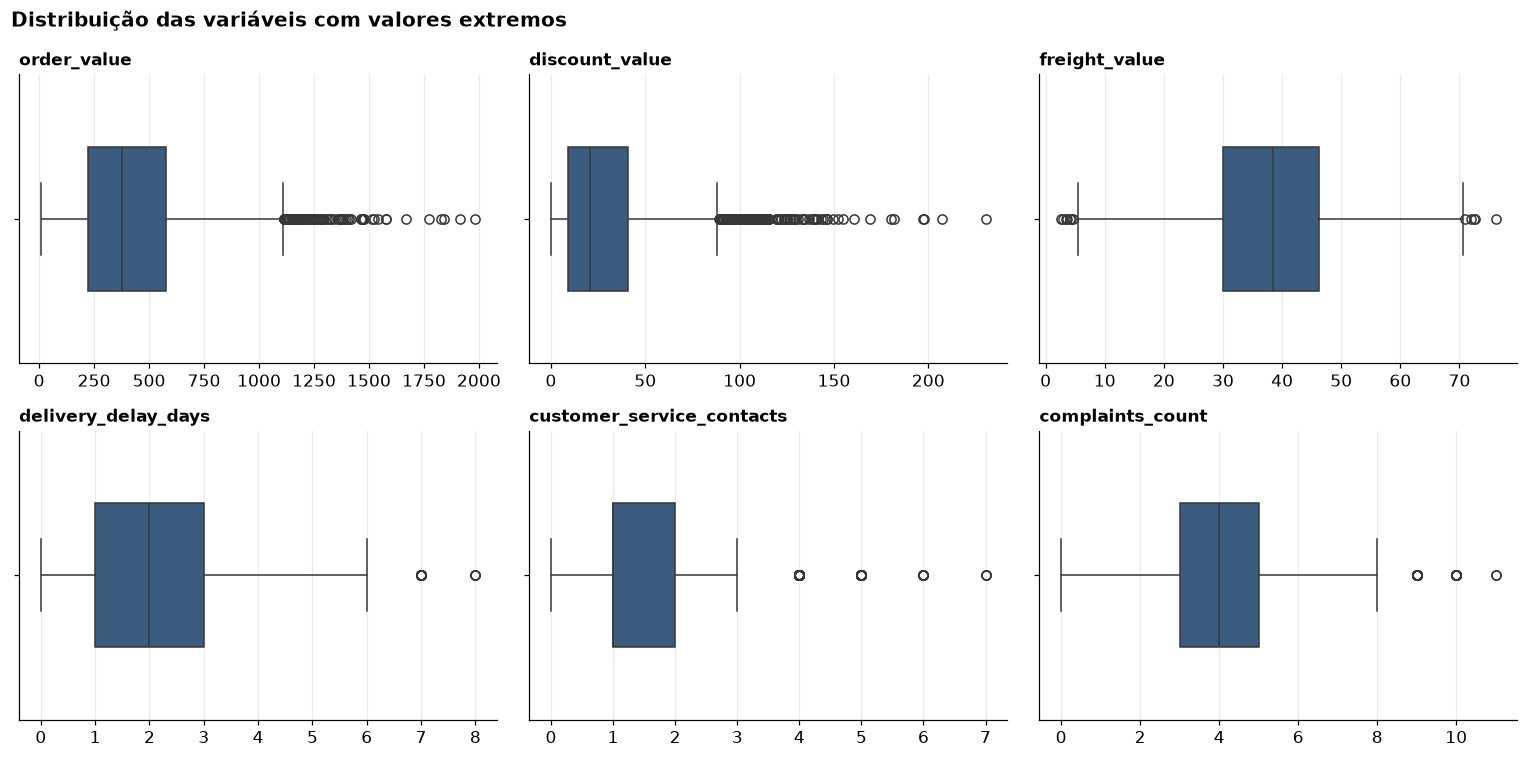

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, column in zip(axes.flat, outlier_columns):
    sns.boxplot(x=raw_df[column], ax=ax, color=config.COLOR_PRIMARY, width=0.5)
    ax.set_title(column, fontsize=11)
    ax.set_xlabel("")
fig.suptitle("Distribuição das variáveis com valores extremos", fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

**Decisão:** manter os outliers.

- Pedidos de valor alto (até ~R$ 2 mil) e descontos altos são **comuns em e-commerce**, não são erro.
- Os casos extremos de atraso (5 a 8 dias) e de muitos contatos com o SAC são justamente os **clientes mais insatisfeitos**. Removê-los esconderia o problema que queremos entender.
- No modelo, isso é tratado com padronização das variáveis e com a comparação de algoritmos baseados em árvores, que são robustos a valores extremos.

## 5. Criação de variáveis derivadas (feature engineering)

Criamos variáveis que facilitam a leitura de negócio. **Todas existem antes da pesquisa de NPS**, então podem ser usadas para prever a nota.

| Variável | Descrição |
|---|---|
| `nps_category` | Detrator (nota < 7), Neutro (7 a < 9) ou Promotor (≥ 9) — regra oficial do NPS |
| `is_detractor` | 1 se o cliente é detrator (alvo da classificação) |
| `has_delay` / `delay_bucket` | Se houve atraso e a faixa de atraso (sem atraso, 1, 2, 3, 4+ dias) |
| `discount_pct` / `freight_pct` | Desconto e frete como % do valor do pedido |
| `ticket_per_item` | Valor médio por item |
| `has_service_contact` | Se o cliente precisou falar com o SAC |
| `complaints_bucket` | Faixa de reclamações (0-1, 2-3, 4-5, 6+) |
| `age_group` / `tenure_group` | Faixa de idade e faixa de tempo de relacionamento |
| `flag_*` | Flags de qualidade identificadas na seção 3 |

In [10]:
processed_df = prepare_dataset(raw_df)
new_columns = [c for c in processed_df.columns if c not in raw_df.columns]
print("Novas colunas:", new_columns)
processed_df[["nps_score"] + new_columns].head()

Novas colunas: ['nps_category', 'is_detractor', 'has_delay', 'delay_bucket', 'discount_pct', 'freight_pct', 'ticket_per_item', 'has_service_contact', 'complaints_bucket', 'age_group', 'tenure_group', 'flag_delay_gt_delivery_time', 'flag_resolution_without_contact', 'flag_discount_gt_order_value']


,nps_score,nps_category,is_detractor,has_delay,delay_bucket,discount_pct,freight_pct,ticket_per_item,has_service_contact,complaints_bucket,age_group,tenure_group,flag_delay_gt_delivery_time,flag_resolution_without_contact,flag_discount_gt_order_value
0,6.9,Detrator,1,1,2 dias,0.2816,0.3974,34.93,0,2-3,60+,1-3 anos,0,1,0
1,2.4,Detrator,1,1,4+ dias,0.0207,0.0615,229.48,0,2-3,18-29,Até 1 ano,0,1,0
2,4.8,Detrator,1,1,1 dia,0.0844,0.0808,101.41,1,6+,40-49,6+ anos,0,0,0
3,5.9,Detrator,1,1,2 dias,0.0648,0.1166,151.10,1,4-5,50-59,6+ anos,0,0,0
4,6.1,Detrator,1,1,1 dia,0.1161,0.1554,253.06,1,2-3,50-59,3-6 anos,0,0,0


In [11]:
category_share = processed_df["nps_category"].value_counts(normalize=True).mul(100).round(1)
print("Distribuição das categorias de NPS (%):")
print(category_share.to_string())
print(f"\nNPS geral da base: {calculate_nps(processed_df['nps_score'])}")

Distribuição das categorias de NPS (%):
nps_category
Detrator    84.4
Neutro      11.2
Promotor     4.4

NPS geral da base: -80.0


## 6. Variáveis que NÃO podem entrar no modelo (risco de vazamento)

O objetivo do negócio é **prever o NPS antes da pesquisa**. Então só podemos usar informações disponíveis **antes** dela.

- `repeat_purchase_30d` (recompra em 30 dias) acontece **depois** do pedido — é uma **consequência** da satisfação, não uma causa.
- `csat_internal_score` é outra **medida de satisfação**, coletada pela própria empresa. Usá-la para prever o NPS seria quase "colar a resposta".

O teste abaixo mostra o tamanho do problema:

In [12]:
repurchase_by_category = (
    processed_df.groupby("nps_category", observed=True)["repeat_purchase_30d"]
    .mean().mul(100).round(1).rename("% que recomprou em 30 dias")
)
repurchase_by_category

nps_category
Detrator      0.0
Neutro       38.4
Promotor    100.0
Name: % que recomprou em 30 dias, dtype: float64

**Leitura:** nenhum detrator recomprou, 38% dos neutros recompraram e **100% dos promotores** recompraram.
A recompra é praticamente um "espelho" da nota. Isso é ótimo para mostrar ao negócio **por que o NPS importa** (ele se converte em receita), mas é péssimo como variável de entrada do modelo. Por isso essas duas variáveis ficam **fora do modelo** e são usadas só na análise.

## 7. Salvando a base tratada

In [13]:
save_processed_data(processed_df)
print(f"Base tratada salva em: {config.DATA_PROCESSED_PATH.relative_to(config.PROJECT_ROOT)}")
print(f"Formato final: {processed_df.shape[0]:,} linhas x {processed_df.shape[1]} colunas")

Base tratada salva em: data/processed/nps_tratado.csv
Formato final: 2,500 linhas x 33 colunas


## Resumo do tratamento

- Base **limpa**: sem nulos e sem duplicados, com tipos corretos.
- **4 inconsistências** de regra de negócio foram encontradas, documentadas e sinalizadas com flags (sem apagar dados).
- **Outliers mantidos**, porque representam situações reais e relevantes para o problema.
- **14 variáveis novas** criadas (incluindo as flags de qualidade) para facilitar a análise.
- `csat_internal_score` e `repeat_purchase_30d` foram **separadas do modelo** por risco de vazamento.

➡️ Próximo passo: `02_analise_exploratoria.ipynb`